# Splicing matrix: alternative splicing variants by sample

One objective: see whether samples fall into groups (endotypes) by the way they splice, using the long-read leafcutter results from S4.

In [1]:
source("src/heatmap.R")   # read_groups, show_heatmap
source("src/splicing.R")
options(repr.plot.width = 10, repr.plot.height = 7)
results_dir <- "../LRP2_test_results"   # change to the results folder of the run
comparison  <- "HepG2_vs_K562"          # prefix of the S4 files
groups <- read_groups(file.path(results_dir, paste0(comparison, ".lr_leafcutter.groups_file.txt")))

**Explanation.** Same two lines to change as in the other notebooks. leafcutter gathers introns that share splice sites into clusters; every intron in a cluster is one splicing variant of that spot in the gene.

In [2]:
subs <- read_subisoforms(file.path(results_dir, paste0(comparison, ".lr_leafcutter.subisoform_clusters.txt")))
sig  <- read_cluster_significance(file.path(results_dir, paste0(comparison, ".lr_leafcutter.ds_cluster_significance.txt")))
eff  <- read_effect_sizes(file.path(results_dir, paste0(comparison, ".lr_leafcutter.ds_effect_sizes.txt")))
x <- subisoform_psi(subs, groups, sig, eff)
dim(x$psi)

[1] 149   8

**Explanation.** For every sample and splicing variant we work out PSI (percent spliced in): the share of that cluster's reads that use the variant, from 0 (never) to 1 (always). The numbers above are the variants and samples in the matrix.

[1] 24

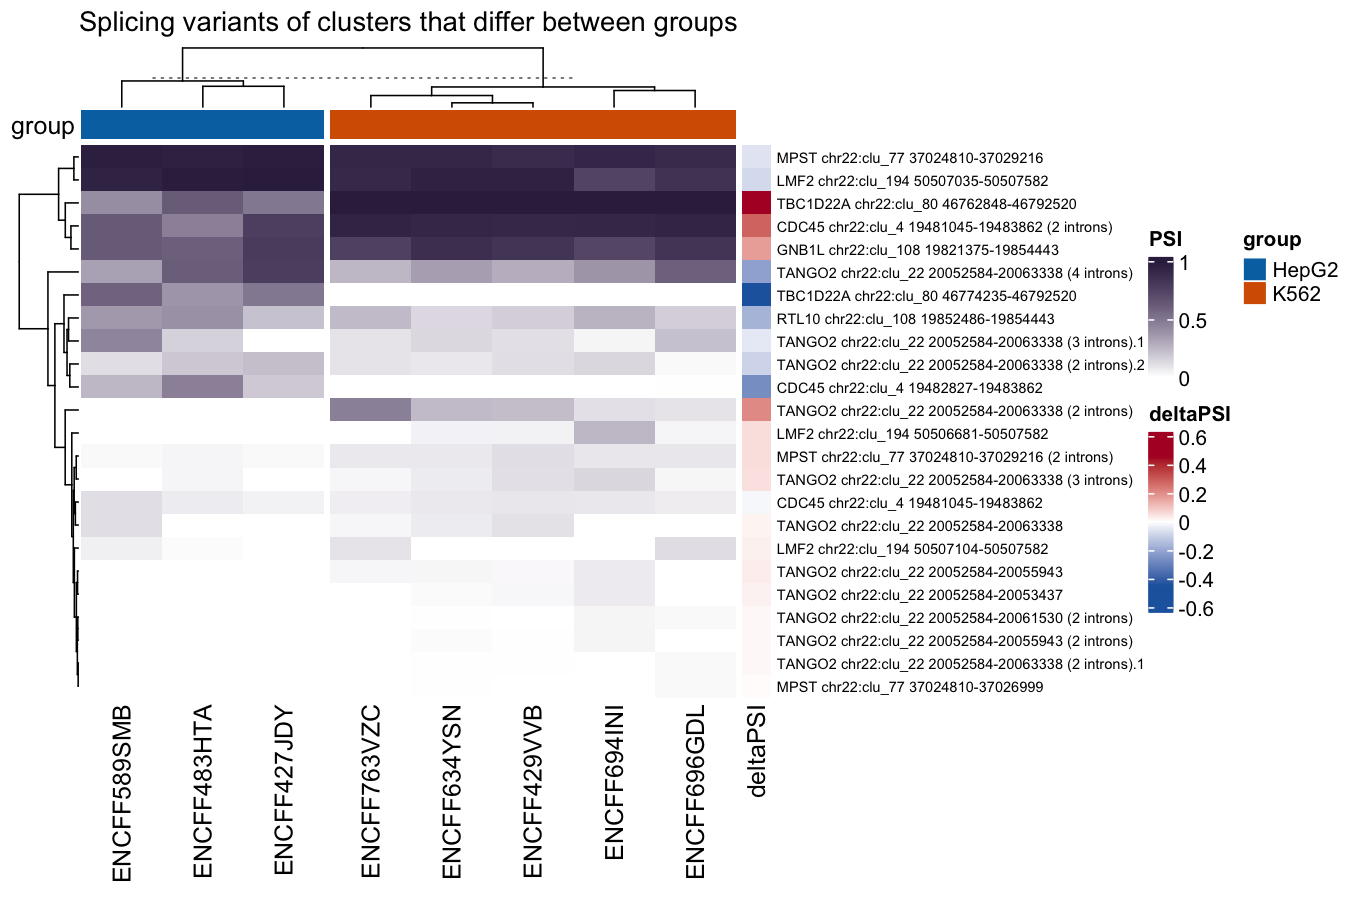

In [3]:
sel <- select_variants(x, alpha = 0.05)
nrow(sel$psi)
show_heatmap(splicing_heatmap(sel, groups, title = "Splicing variants of clusters that differ between groups"), "splicing_heatmap", height = 6)

**Explanation.** Rows are the splicing variants (named by gene, cluster and the first and last splice position; a variant with several introns says how many) of the clusters leafcutter found different between the groups (adjusted p below 0.05); columns are samples split by group. Dark means the sample uses that variant often. The bar at the right is the change in PSI between the groups (second group minus first). Samples that clutter together by pattern, rather than by group, are candidate endotypes. Grey means the cluster had no reads in that sample.

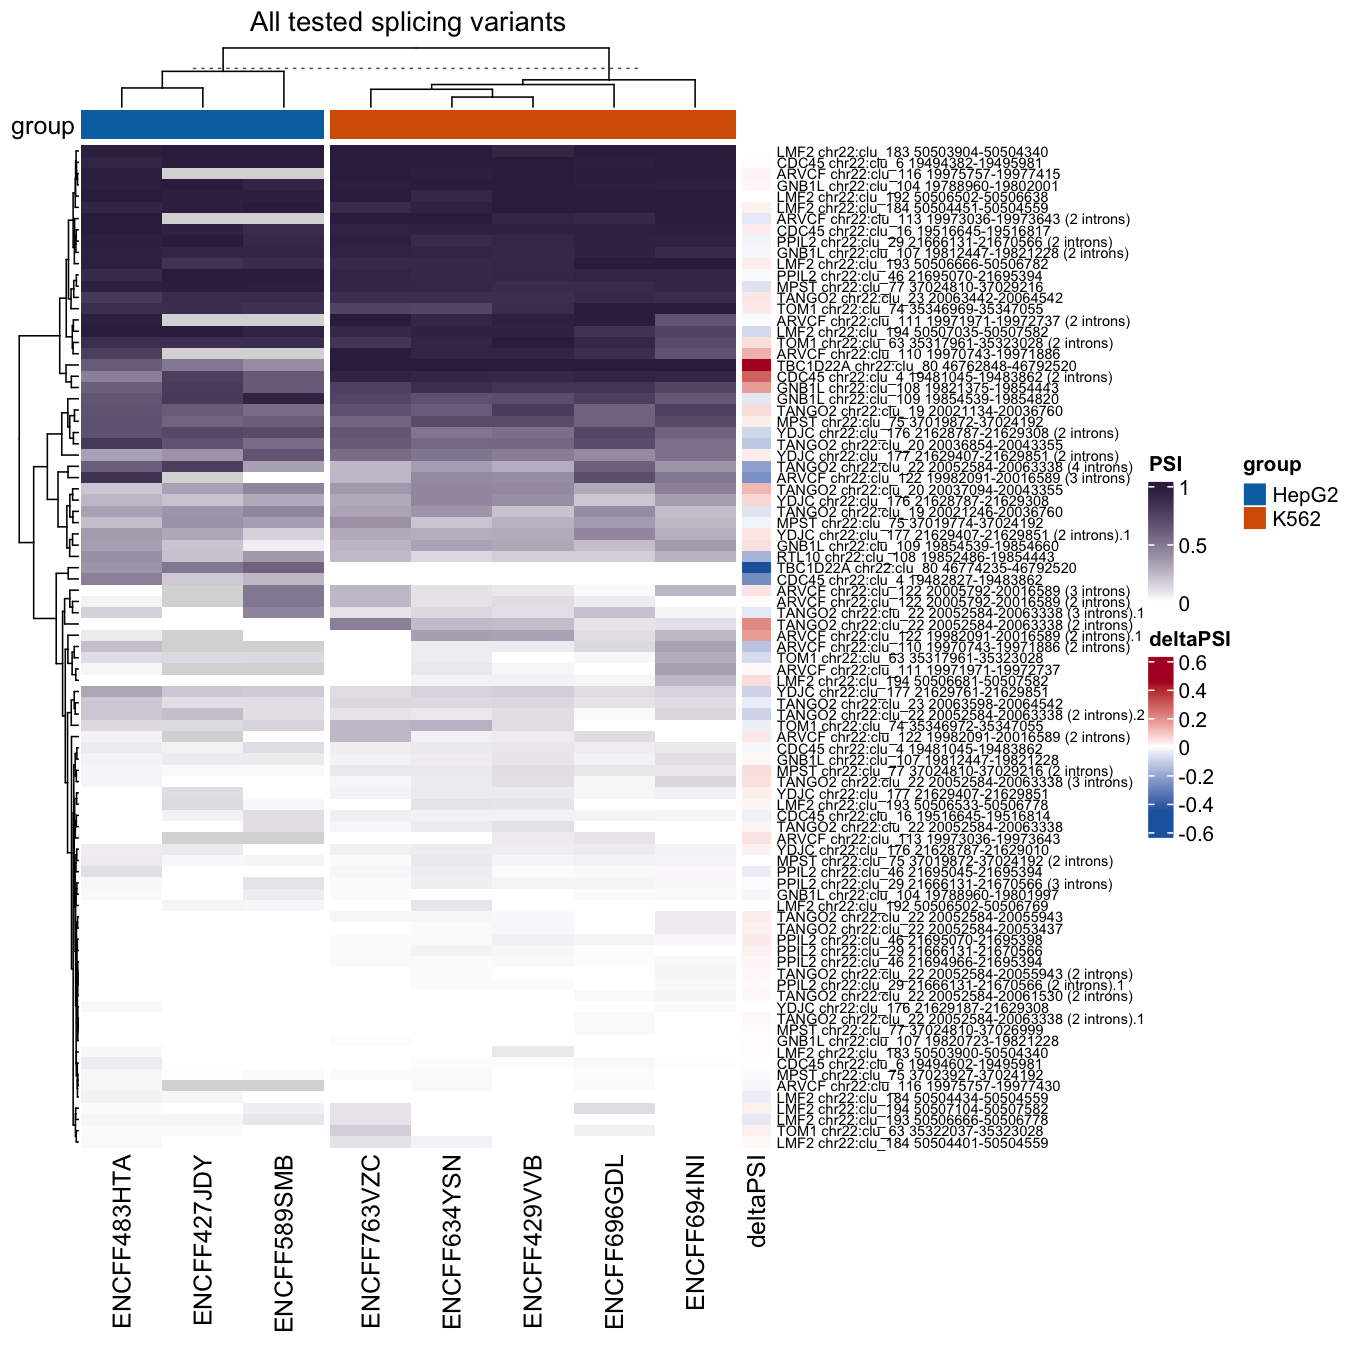

In [4]:
all_multi <- select_variants(x, alpha = 1)
show_heatmap(splicing_heatmap(all_multi, groups, title = "All tested splicing variants"), "splicing_heatmap_all", height = 9)

**Explanation.** The same matrix for every cluster that was tested, not only the ones that differ between the groups. This is where an endotype would show up as a split inside one group.